# Task 3 — Arithmetic Operations: Add, Subtract, Multiply, Divide

In [1]:
# Step 1 — Import and Load Image(s)

import cv2
import numpy as np
import matplotlib.pyplot as plt

def show(images, titles, cols=4):
    n = len(images)
    rows = (n + cols - 1) // cols
    plt.figure(figsize=(4 * cols, 4 * rows))
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i + 1)
        if len(img.shape) == 3:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(img, cmap='gray', vmin=0, vmax=255)
        plt.title(title)
        plt.axis('off')
    plt.tight_layout()
    plt.show()


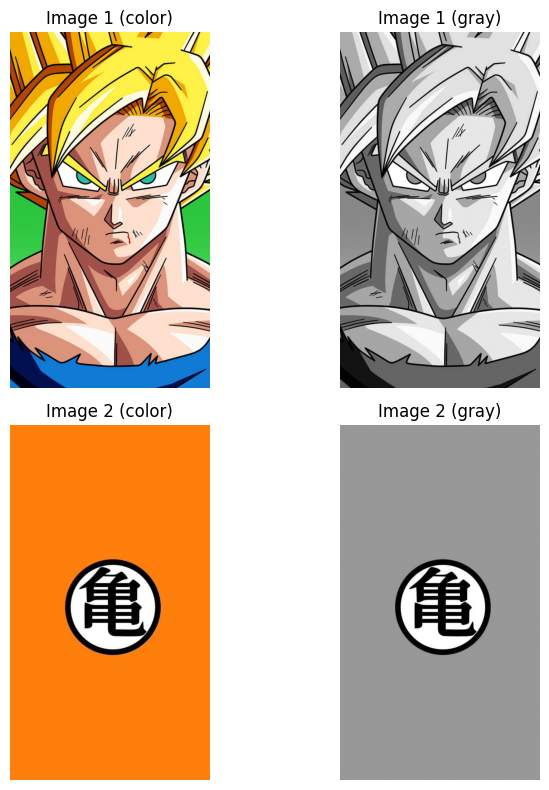

In [2]:
# Load both images and convert to grayscale
c1 = cv2.imread('image1.jpg')
c2 = cv2.imread('image2.jpg')
img1 = cv2.cvtColor(c1, cv2.COLOR_BGR2GRAY)
img2 = cv2.cvtColor(c2, cv2.COLOR_BGR2GRAY)
# Resize image2 to match image1
img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))

show([c1, img1, c2, img2], ['Image 1 (color)', 'Image 1 (gray)',
                            'Image 2 (color)', 'Image 2 (gray)'], cols=2)


## Step 2 — Apply Arithmetic Operations

OpenCV's arithmetic functions clip (saturate) results to the 0–255 range instead of wrapping around.

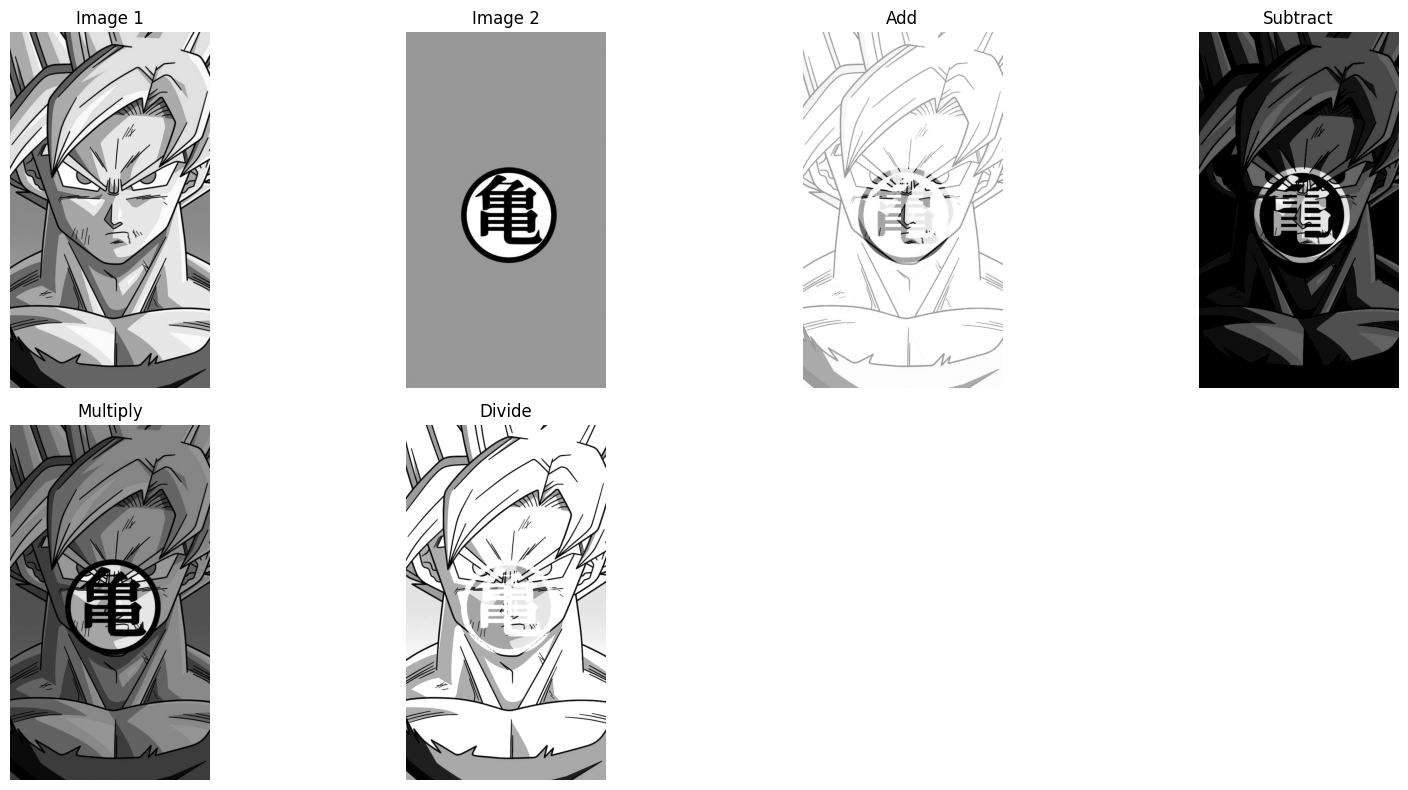

In [3]:
add_img = cv2.add(img1, img2)                        # Add
sub_img = cv2.subtract(img1, img2)                 # Subtract
mul_img = cv2.multiply(img1.astype(np.float32),
                       img2.astype(np.float32)/255)  # Multiply (normalize)
mul_img = np.clip(mul_img, 0, 255).astype(np.uint8)
div_img = cv2.divide(img1.astype(np.float32),
                     img2.astype(np.float32) + 1e-5)  # Divide (avoid /0)
div_img = np.clip(div_img * 255, 0, 255).astype(np.uint8)

show([img1, img2, add_img, sub_img, mul_img, div_img],
     ['Image 1', 'Image 2', 'Add', 'Subtract', 'Multiply', 'Divide'])
